In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
from src.data_loader import load_pjm_data
from sklearn.metrics import mean_absolute_error, mean_squared_error

df = load_pjm_data("../data/raw/PJME_hourly.csv")

# Prophet requires exactly two columns named "ds" (datetime) and "y" (target)
df_p = df.loc["2016-01-01":].reset_index()
df_p.columns = ["ds", "y"]

# Hold out the last 30 days, matching the final walk-forward fold from the ML phase
train = df_p.iloc[:-720]
test = df_p.iloc[-720:]

print(train.shape, test.shape)
print("Train ends:", train["ds"].max())
print("Test starts:", test["ds"].min())

(21961, 2) (720, 2)
Train ends: 2018-07-04 00:00:00
Test starts: 2018-07-04 01:00:00


In [2]:
from prophet import Prophet

m = Prophet(
    daily_seasonality=True,
    weekly_seasonality=True,
    yearly_seasonality=True,
    seasonality_mode="additive",
)
m.fit(train)

Importing plotly failed. Interactive plots will not work.
13:00:29 - cmdstanpy - INFO - Chain [1] start processing
13:00:50 - cmdstanpy - INFO - Chain [1] done processing


In [3]:
forecast = m.predict(test[["ds"]])

preds = forecast["yhat"].values
mae = mean_absolute_error(test["y"], preds)
rmse = np.sqrt(mean_squared_error(test["y"], preds))

print(f"Prophet Test MAE: {mae:.2f}")
print(f"Prophet Test RMSE: {rmse:.2f}")

Prophet Test MAE: 4699.59
Prophet Test RMSE: 5619.37


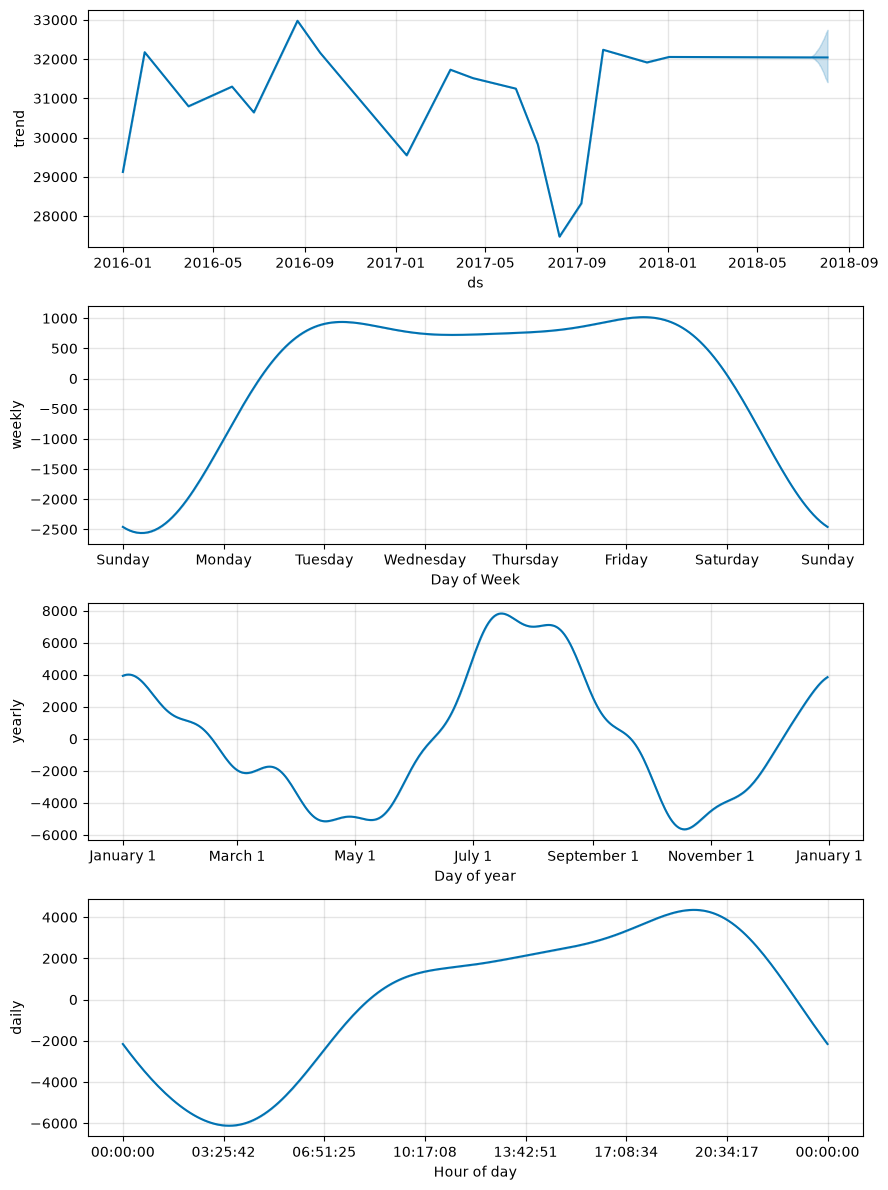

In [4]:
full_forecast = m.predict(df_p[["ds"]])
fig = m.plot_components(full_forecast)

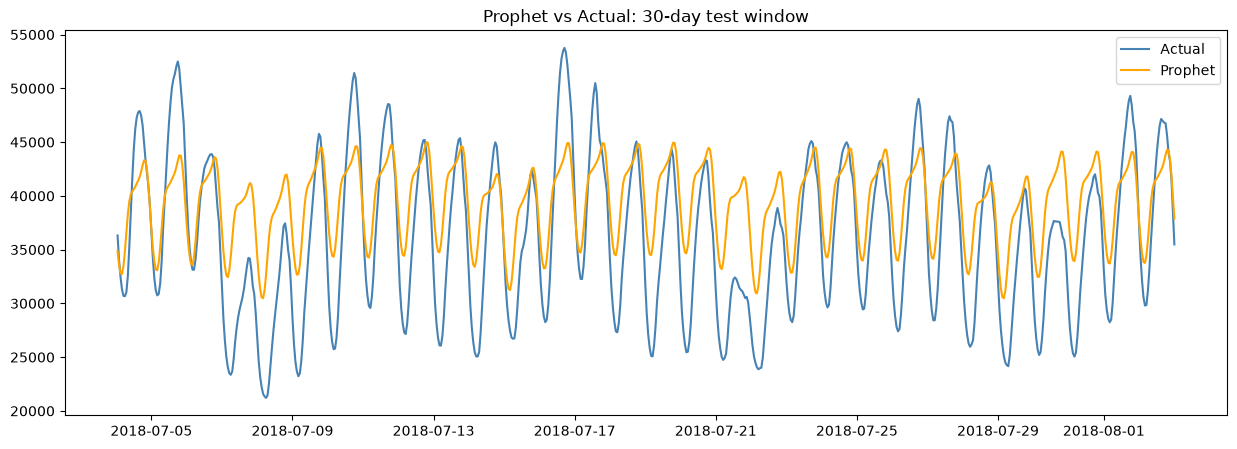

Mean error (pred - actual): 3222.6119672430227


In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(test["ds"], test["y"].values, label="Actual", color="steelblue")
ax.plot(test["ds"], preds, label="Prophet", color="orange")
ax.set_title("Prophet vs Actual: 30-day test window")
ax.legend()
plt.show()

print("Mean error (pred - actual):", (preds - test["y"].values).mean())

In [6]:
recent = train.iloc[-672:].copy()  # last 4 weeks
recent["how"] = recent["ds"].dt.dayofweek * 24 + recent["ds"].dt.hour
profile = recent.groupby("how")["y"].mean()

test_how = test["ds"].dt.dayofweek * 24 + test["ds"].dt.hour
baseline_preds = test_how.map(profile).values

mae_b = mean_absolute_error(test["y"], baseline_preds)
print(f"4-week hour-of-week baseline MAE: {mae_b:.2f}")

4-week hour-of-week baseline MAE: 4038.71


In [7]:
def add_conditions(d):
    d = d.copy()
    summer = d["ds"].dt.month.isin([6, 7, 8, 9])
    weekend = d["ds"].dt.dayofweek >= 5
    d["summer_weekday"] = summer & ~weekend
    d["summer_weekend"] = summer & weekend
    d["other_weekday"] = ~summer & ~weekend
    d["other_weekend"] = ~summer & weekend
    return d

train_c = add_conditions(train)
test_c = add_conditions(test)

m2 = Prophet(
    daily_seasonality=False,   # replaced by the four conditional daily shapes
    weekly_seasonality=True,
    yearly_seasonality=True,
    seasonality_mode="additive",
)

for cond in ["summer_weekday", "summer_weekend", "other_weekday", "other_weekend"]:
    m2.add_seasonality(name=f"daily_{cond}", period=1, fourier_order=8, condition_name=cond)

m2.fit(train_c)

13:06:25 - cmdstanpy - INFO - Chain [1] start processing
13:07:23 - cmdstanpy - INFO - Chain [1] done processing


Prophet (conditional) MAE: 4514.75
Prophet (conditional) RMSE: 5274.42
Mean error (pred - actual): 3915.179811463252


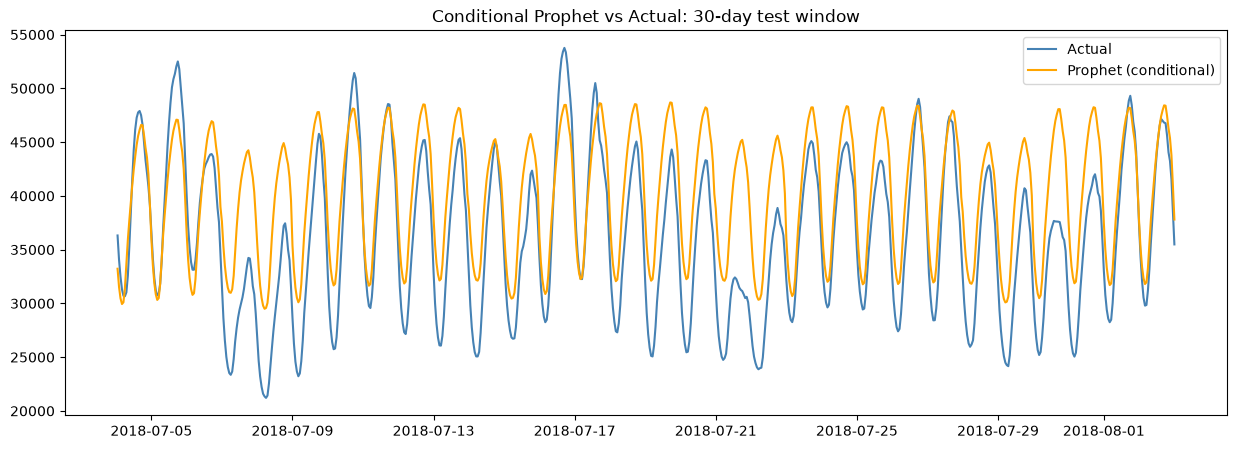

In [8]:
forecast2 = m2.predict(test_c)
preds2 = forecast2["yhat"].values

mae2 = mean_absolute_error(test["y"], preds2)
rmse2 = np.sqrt(mean_squared_error(test["y"], preds2))
print(f"Prophet (conditional) MAE: {mae2:.2f}")
print(f"Prophet (conditional) RMSE: {rmse2:.2f}")
print("Mean error (pred - actual):", (preds2 - test["y"].values).mean())

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(test["ds"], test["y"].values, label="Actual", color="steelblue")
ax.plot(test["ds"], preds2, label="Prophet (conditional)", color="orange")
ax.set_title("Conditional Prophet vs Actual: 30-day test window")
ax.legend()
plt.show()

In [9]:
bias = (preds2 - test["y"].values).mean()
print("MAE with the average bias removed (diagnostic only):",
      np.abs(preds2 - bias - test["y"].values).mean())

MAE with the average bias removed (diagnostic only): 2794.1297839211393


In [10]:
import os
import mlflow

db_path = os.path.abspath("../mlflow.db")
mlflow.set_tracking_uri(f"sqlite:///{db_path}")
mlflow.set_experiment("EnergyForecast")

rmse_b = np.sqrt(mean_squared_error(test["y"], baseline_preds))

prophet_runs = [
    ("Prophet (default)", mae, rmse, "additive, daily+weekly+yearly, blind 30-day forecast"),
    ("Prophet (conditional)", mae2, rmse2, "4 conditional daily seasonalities, blind 30-day forecast"),
    ("4-week hour-of-week baseline", mae_b, rmse_b, "blind 30-day forecast, no model"),
]

for name, m_mae, m_rmse, notes in prophet_runs:
    with mlflow.start_run(run_name=name):
        mlflow.log_param("model_type", name)
        mlflow.log_param("notes", notes)
        mlflow.log_param("eval_window", "last 720 hours (Fold 5 window)")
        mlflow.log_metric("MAE", m_mae)
        mlflow.log_metric("RMSE", m_rmse)

print("Logged Prophet runs to MLflow")

Logged Prophet runs to MLflow
